In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from tabulate import tabulate

from sklearn.model_selection import train_test_split
import torch

# Custom modules
import LSTM
import Dataset


# Set SEED
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## Data loading

In [16]:
df = pd.read_parquet('../Data/LOBSTER/AMZN.parquet', columns=['P_Ask_1'])
# df = pd.read_parquet('../Data/Toy Datasets/sinewave.parquet')
df.head()

,P_Ask_1
0,2239500
1,2239500
2,2239500
3,2239500
4,2239500


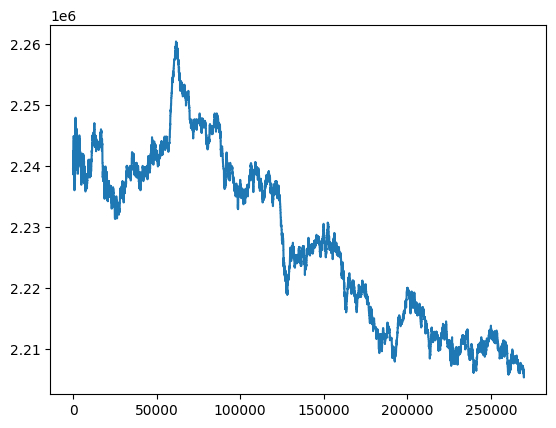

In [17]:
plt.plot(df['P_Ask_1'])
plt.show()

In [22]:
# Split the dataframe into train and test
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=False)
X_train, X_test = df_train.values, df_test.values
X_train = X_train
X_test = X_test

# Build tensors 
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)

# Build TimeSeriesDataset
SEQ_LEN_X = 100
SEQ_LEN_Y = 1
OFFSET = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = X_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = X_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False
)

# Build TimeSeriesLoader
BATCH_SIZE = 128
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = BATCH_SIZE,
    shuffle = False
)

In [23]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 215738 samples
Test dataset: 53890 samples


## Model

In [24]:
# define hyperparameters
INPUT_SIZE = X_train.shape[-1]
OUTPUT_SIZE = X_train.shape[-1]
HIDDEN_SIZE = 8
LSTM_LAYERS = 2
DROPOUT = 0.0
NUM_CHANNELS = 2

# Show hyperparameters in a pretty table
table = [
    ["INPUT_SIZE", INPUT_SIZE],
    ["OUTPUT_SIZE", OUTPUT_SIZE],
    ["HIDDEN_SIZE", HIDDEN_SIZE],
    ["LSTM_LAYERS", LSTM_LAYERS],
    ["DROPOUT", DROPOUT],
]
print(tabulate(table, headers=["Parameter", "Value"], tablefmt="pretty"))

# create the model
model = LSTM.Astice(
    input_size  = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    lstm_layers = LSTM_LAYERS,
    smooth_conv_channels = 2
).to(device)

+-------------+-------+
|  Parameter  | Value |
+-------------+-------+
| INPUT_SIZE  |   1   |
| OUTPUT_SIZE |   1   |
| HIDDEN_SIZE |   8   |
| LSTM_LAYERS |   2   |
|   DROPOUT   |  0.0  |
+-------------+-------+


### Training

In [25]:
NUM_EPOCHS = 5
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
criterion = torch.nn.MSELoss()

progress_bar = tqdm(range(NUM_EPOCHS), desc="Training")
losses_train = []
for i in progress_bar:
    model.train()
    for X_batch, y_batch in dataloader_train:
        optimizer.zero_grad()
        y_pred = model(X_batch)
        
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
    
    model.eval()
    with torch.no_grad():
        loss_train = 0
        for X_batch, y_batch in dataloader_train:
            y_pred = model(X_batch)
            loss_train += criterion(y_pred, y_batch).item()
        loss_train /= len(dataloader_train)
        losses_train.append(loss_train)
    progress_bar.set_postfix({'loss_train': loss_train})
    

Training:   0%|          | 0/5 [00:00<?, ?it/s]

In [26]:
print('Total number of parameters: ', sum(p.numel() for p in model.parameters()))

Total number of parameters:  1333


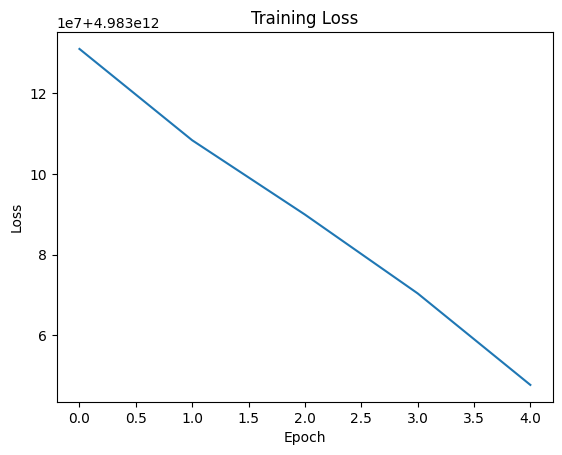

In [27]:
plt.plot(losses_train)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [34]:
# predict test set and calculate loss
model.eval()
loss_test = 0
preds = []
true = []
with torch.no_grad():
    for X_batch, y_batch in dataloader_test:
        y_pred = model(X_batch)
        loss_test += criterion(y_pred, y_batch).item()
        preds.append( y_pred.cpu().numpy() )
        true.append( y_batch.cpu().numpy() )
loss_test /= len(dataloader_test)
print(f"Test Loss: {loss_test}")

preds = np.concatenate(preds, axis=0)
true = np.concatenate(true, axis=0)

Test Loss: 4884266923517.573


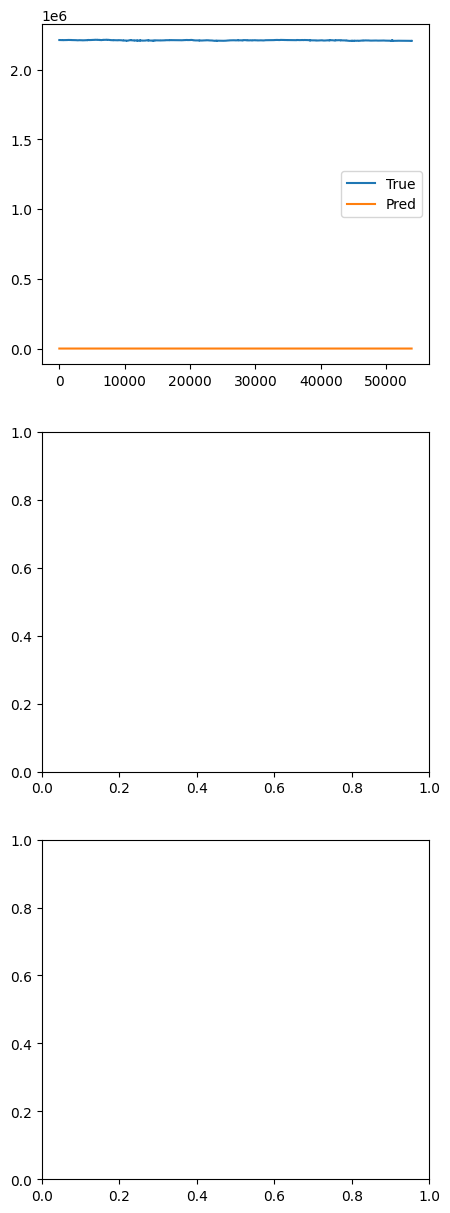

In [35]:
true, pred = true[:,0,:], preds[:,0,:]
fig, ax = plt.subplots(3, 1, figsize=(5, 15))
for i in range(true.shape[-1]):
    ax[i].plot(true[:,i], label="True")
    ax[i].plot(pred[:,i], label="Pred")
    ax[i].legend()
plt.show()